In [1]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

In [2]:
# Creating registers
q = QuantumRegister(name='q', size=3)
c = ClassicalRegister(name='c', size=3)

# Creates the quantum circuit
teleport = QuantumCircuit(q, c)

# Step 0 - Instantiate qubit 0 in the state to be teleported:
teleport.h(0)
teleport.s(0)
teleport.barrier()

# Step 1 - Make the shared entangled state in between qubit 1 and qubit 2
teleport.h(1)
teleport.cx(1, 2)
teleport.barrier()

# Step 2 & 3: Alice applies a series of gates on qubit 0 and qubit 1
teleport.cx(0, 1)
teleport.h(0)

# Step 4 - Alice measures qubit 0 and qubit 1
teleport.measure(0, 0)
teleport.measure(1, 1)

# Step 5 - Bob applies a unitary transformation on his qubit
# based on the outcome of Alice's measurements
teleport.cx(1, 2)
teleport.cz(0, 2)

teleport.barrier()

# Step 6 - Bob checks if he got the right state
teleport.s(2)
teleport.s(2)
teleport.s(2)
teleport.h(2)
teleport.measure(2, 2)

# Visualizing your teleportation circuit
teleport.draw()

┌───┐┌───┐ ░            ░      ┌───┐┌─┐         ░                        
q_0: ┤ H ├┤ S ├─░────────────░───■──┤ H ├┤M├──────■──░────────────────────────
     └───┘└───┘ ░ ┌───┐      ░ ┌─┴─┐└┬─┬┘└╥┘      │  ░                        
q_1: ───────────░─┤ H ├──■───░─┤ X ├─┤M├──╫───■───┼──░────────────────────────
                ░ └───┘┌─┴─┐ ░ └───┘ └╥┘  ║ ┌─┴─┐ │  ░ ┌───┐┌───┐┌───┐┌───┐┌─┐
q_2: ───────────░──────┤ X ├─░────────╫───╫─┤ X ├─■──░─┤ S ├┤ S ├┤ S ├┤ H ├┤M├
                ░      └───┘ ░        ║   ║ └───┘    ░ └───┘└───┘└───┘└───┘└╥┘
c: 3/═════════════════════════════════╩═══╩═════════════════════════════════╩═
                                      1   0                                 2

If the state at the end of the circuit is indeed the state $|\phi\rangle$, and if we apply to it the inverse gates of its instantiation by Alice, then we must measure the state $|0\rangle$, because that is the state we started from.

The inverse of $S$ is $S^3$.

The counts for circuit teleport are: {'010': 1998, '001': 2079, '000': 2057, '011': 2058}


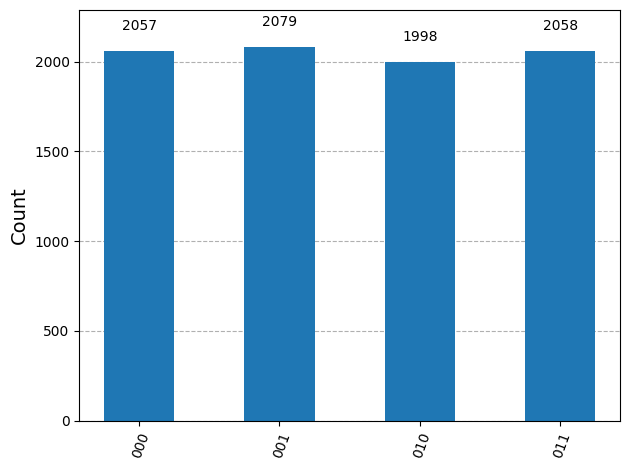

In [35]:
backend = BasicSimulator()
result = backend.run(teleport, shots=8192).result()
counts = result.get_counts()
print(f"The counts for circuit teleport are: {counts}")
plot_histogram(counts)